# Peak width and height across a GC-MS screening design

**Question:** Which of the seven parameters significantly change peak width or height, and are they the same for early- and late-eluting standards?

**Data:** Gamble, S.; Granger, C.; Mannion, J. *GC-MS Screening Data for Instrument Optimization*. figshare, 2025. https://doi.org/10.6084/m9.figshare.28635920.v1 (license GPL 3.0+). Accessed 2026-11-08.

## Imports

Purpose: load the libraries used below. Expected output: none.

In [1]:
import itertools
import sys

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

## Parameters

Purpose: numbers that encode a choice about these data. `N_METHODS` comes from the design: a two-level fractional factorial in seven factors with 32 runs. Expected output: none.

In [2]:
N_METHODS = 32  # runs in the design (ffd.csv), one chromatogram each
TIC_HEADER_LINES = 2  # text lines before the data in each TIC file: run name, "Start of data points"

Peak-measurement parameters, chosen from the data before any effects are computed: the peak full widths at half height (FWHM) run from 0.022 to 0.067 min and data points are 0.0036 min apart; the closest pair of standards (iodohexane and iodobenzene in Method 24) is 0.625 min apart; the earliest standard (iodopropane in Method 12) elutes at 4.12 min, and recording starts at 4.00 min.

In [3]:
PEAK_WINDOW_MIN = 0.15  # min, half-width of the window around each listed retention time: > 2 x the widest FWHM (0.067 min), < half the closest gap between standards (0.625 min)
CHECK_WINDOW_MIN = 0.25  # min, a wider window used only to test whether a result depends on the window
BASELINE_EDGE_POINTS = 5  # points in the moving average used to find the valleys and set the baseline level there (5 x 0.0036 = 0.018 min)
APEX_TOLERANCE_MIN = 0.01  # min, largest allowed distance from apex to listed retention time: about half the narrowest FWHM
MIN_POINTS_ACROSS = 5  # data points across the FWHM below which the width is not trusted
WINDOW_SENSITIVITY = 0.10  # fraction, largest allowed change in height or width between the two windows
NOISE_INNER_MIN = 0.20  # min, noise is estimated from 0.20 to 0.45 min either side of the listed time: outside the ±0.15 min window,
NOISE_OUTER_MIN = 0.45  # min, and inside the closest gap between standards (0.625 min), so it holds baseline only
MIN_SIGNAL_TO_NOISE = 10  # height / noise below which a peak is flagged: the usual limit for a quantifiable peak
FLAT_TOP_POINTS = 3  # raw points sharing the apex value at or above which a peak is flagged as possibly saturated
NEIGHBOR_PROMINENCE = 0.05  # fraction of the peak's height: another peak at least this prominent inside the window is flagged as a neighbor

## Load the data

Purpose: read the design, the retention times and all 32 chromatograms from `data/`, exactly as downloaded.

Scientific choice: each TIC file starts with a byte-order mark and two text lines, so it is read with `skiprows=TIC_HEADER_LINES` and `encoding="utf-8-sig"`. The 32 chromatograms are stacked into one long table with a `method` column, so later steps can work on one method at a time with `groupby`. Nothing in the files is edited.

One row of `design` is one method and its seven factor levels (A to G). One row of `retention_times` is one method's retention time for each of the 11 standards, in min. One row of `tic` is one time point of one chromatogram: time in min and total ion current in counts.

Expected output: 32 rows in `design` and in `retention_times`, and about 425,000 rows in `tic`.

In [4]:
def read_tic(method):
    """Read one chromatogram as downloaded.

    Parameters
    ----------
    method : int
        Method number, 1 to N_METHODS.

    Returns
    -------
    pandas.DataFrame
        Columns `method`, `time` (min) and `intensity` (counts).
    """
    chromatogram = pd.read_csv(
        f"data/TIC_Method_{method}.csv",
        skiprows=TIC_HEADER_LINES,
        header=None,
        names=["time", "intensity"],  # min, counts
        encoding="utf-8-sig",
    )
    chromatogram.insert(0, "method", method)
    return chromatogram


design = pd.read_csv("data/ffd.csv")  # factor levels per method, columns A-G
retention_times = pd.read_csv("data/rts.csv", index_col="Chemical")  # min
tic = pd.concat(
    [read_tic(method) for method in range(1, N_METHODS + 1)], ignore_index=True
)  # time in min, intensity in counts

print(f"design: {len(design)} rows, columns {list(design.columns)}")
print(f"retention_times: {len(retention_times)} rows, {len(retention_times.columns)} standards")
print(f"tic: {len(tic)} rows, columns {list(tic.columns)}")

design: 32 rows, columns ['Method', 'A', 'B', 'C', 'D', 'E', 'F', 'G']
retention_times: 32 rows, 11 standards
tic: 425125 rows, columns ['method', 'time', 'intensity']


## Check for problems on loading

Purpose: look for missing or non-numeric values, check the column types, and check that the three tables name the same 32 methods.

Scientific choice: a value that could not be read as a number would show up as an `object` column or a missing value. The method names in `rts.csv` ("Method 1") differ in format from the numbers in `ffd.csv` (1), so they are compared after taking the number off the name.

Expected output: zero missing values, numeric columns everywhere, and empty sets for the methods missing from either table. Per method, the number of points and the time range in min.

In [5]:
print("missing values:")
print(f"  design {design.isna().sum().sum()}, "
      f"retention_times {retention_times.isna().sum().sum()}, "
      f"tic {tic.isna().sum().sum()}")
print("column types in tic:", dict(tic.dtypes.astype(str)))

rts_methods = set(retention_times.index.str.split(" ").str[1].astype(int))
design_methods = set(design["Method"])
tic_methods = set(tic["method"])
print("in design but not in rts:", design_methods - rts_methods)
print("in design but not in tic:", design_methods - tic_methods)

per_method = tic.groupby("method").agg(
    points=("time", "size"),
    start=("time", "min"),  # min
    end=("time", "max"),  # min
    max_intensity=("intensity", "max"),  # counts
    min_intensity=("intensity", "min"),  # counts
)
print()
print(per_method.to_string())

missing values:
  design 0, retention_times 0, tic 0
column types in tic: {'method': 'int64', 'time': 'float64', 'intensity': 'float64'}
in design but not in rts: set()
in design but not in tic: set()

        points    start       end  max_intensity  min_intensity
method                                                         
1        16245  4.00090  63.00315   1.010000e+09       35608.15
2        10325  4.00150  41.50165   4.290466e+07       34513.53
3        10326  4.00088  41.50185   4.210000e+08       29572.80
4        16246  4.00088  63.00403   5.690000e+08       35154.72
5        10326  4.00088  41.50322   1.130000e+09       36803.97
6        16244  4.00088  63.00222   2.350000e+07       26807.25
7        16245  4.00088  63.00175   2.930000e+08       31755.22
8        10326  4.00090  41.50163   7.870000e+08       37031.79
9        16244  4.00088  63.00063   2.100000e+07       29754.72
10       10325  4.00088  41.50137   9.810000e+08       37018.94
11       10326  4.00088  41.50

## Raw chromatograms with the listed retention times

Purpose: before measuring any peak, check that the retention times in `rts.csv` sit on real peaks in the TIC, and look at the baseline and at anything that is not one of the 11 standards.

Scientific choice: the two methods are picked from the data, not by hand: the slowest method (latest iodododecane retention time) and the fastest (earliest), so together they bracket the design. Each gets its own panel because their peak heights differ about 30-fold. The y-axis is capped at 1.2 times the tallest standard so the standards stay readable; the cell prints the largest value the cap hides and where it is.

Expected output: two panels of intensity (counts) against time (min), a dashed line numbered 1 to 11 at each standard's listed retention time, and one printed line per method about what is above the axis.

Method 22: largest value 9.76e+08 counts at 5.61 min is above the axis; clipped points span 5.04-6.95 min
Method 3: nothing clipped
numbers 1-11: iodopropane, iodobutane, iodopentane, iodohexane, iodobenzene, iodoheptane, iodooctane, iodononane, iododecane, iodoundecane, iodododecane


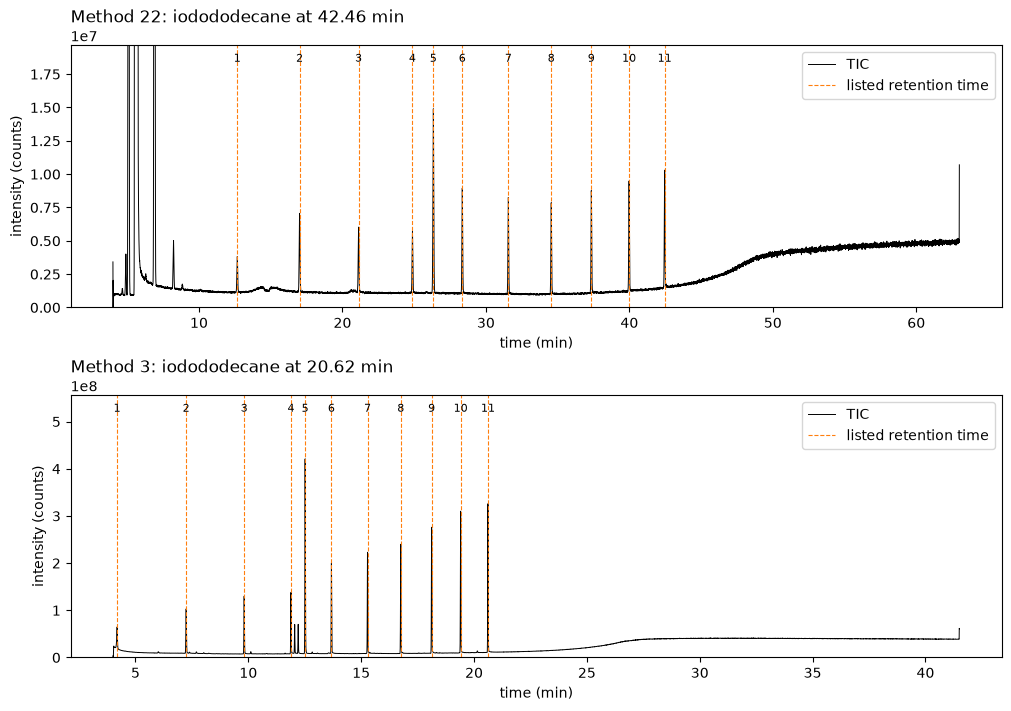

In [6]:
last_standard = retention_times.columns[-1]  # iodododecane, elutes last
example_labels = [
    retention_times[last_standard].idxmax(),  # slowest method
    retention_times[last_standard].idxmin(),  # fastest method
]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), layout="constrained")
for ax, label in zip(axes, example_labels):
    method = int(label.split(" ")[1])
    chromatogram = tic[tic["method"] == method]
    time = chromatogram["time"].to_numpy()  # min
    intensity = chromatogram["intensity"].to_numpy()  # counts
    method_rts = retention_times.loc[label].to_numpy()  # min

    # tallest standard: TIC value at each listed retention time, counts
    standard_heights = np.interp(method_rts, time, intensity)
    y_cap = 1.2 * standard_heights.max()  # counts, display only

    ax.plot(time, intensity, color="black", linewidth=0.7, label="TIC")
    for number, rt in enumerate(method_rts, start=1):
        ax.axvline(rt, color="tab:orange", linestyle="--", linewidth=0.8,
                   label="listed retention time" if number == 1 else None)
        ax.text(rt, 1.02 * y_cap, str(number), ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, 1.1 * y_cap)
    ax.set_xlabel("time (min)")
    ax.set_ylabel("intensity (counts)")
    ax.set_title(f"{label}: {last_standard} at {retention_times.loc[label, last_standard]:.2f} min",
                 loc="left")
    ax.legend(loc="upper right")

    clipped = intensity > 1.1 * y_cap
    if clipped.any():
        print(f"{label}: largest value {intensity.max():.3g} counts at "
              f"{time[intensity.argmax()]:.2f} min is above the axis; "
              f"clipped points span {time[clipped].min():.2f}-{time[clipped].max():.2f} min")
    else:
        print(f"{label}: nothing clipped")

print("numbers 1-11:", ", ".join(retention_times.columns))
plt.show()

In both the slowest and the fastest method each of the 11 dashed lines falls on a peak, so `rts.csv` can locate the peaks; the off-scale peaks between 5.0 and 7.0 min in Method 22 are not standards, and in Method 3 iodopropane (1) elutes only 0.19 min after recording starts at 4.0 min, on the falling edge of the start of the trace.

## Measure height and width of every peak

Purpose: measure the height (counts) and the full width at half maximum (FWHM, min) of each of the 11 standards in each of the 32 methods, 352 peaks, and flag those that cannot be trusted.

Scientific choices:
- The search window is the listed retention time ± `PEAK_WINDOW_MIN`. Step 1 showed the listed times sit on the peaks. The apex is the highest point in the window.
- The baseline is a straight line between the valleys on either side of the apex, found by walking outward from the apex on a `BASELINE_EDGE_POINTS`-point moving average until the signal stops falling (or the window ends). This valley-to-valley baseline is used because some standards have an unlisted neighboring peak inside the window (for example about 0.12 min before iodohexane in Methods 11, 15, 19, 23 and 25); a baseline drawn between the window edges would then start on the neighbor's flank and cut the height. A sloping baseline, such as the falling start of the trace under early iodopropane, is still removed.
- Height is the apex above that baseline. FWHM is found by walking out from the apex, between the two valleys only, to where the signal drops below half the height, and interpolating linearly between the points either side of that crossing, so widths are not limited to multiples of the 0.0036 min point spacing.
- A peak is flagged if its apex is more than `APEX_TOLERANCE_MIN` from the listed time; if fewer than `MIN_POINTS_ACROSS` points span its FWHM; if its window runs past the start of the recording; if remeasuring it with `CHECK_WINDOW_MIN` changes its height or width by more than `WINDOW_SENSITIVITY`; if `FLAT_TOP_POINTS` or more raw points share its apex value, as a saturated detector would produce; or if another peak at least `NEIGHBOR_PROMINENCE` of its height lies inside the window. Flagged peaks are kept in the table, so that excluding them is a separate, visible decision.

Expected output: a table `peaks` with 352 rows; a summary of heights (about 10⁶ to 10⁸ counts) and widths (about 0.02 to 0.07 min); the number of peaks raising each flag; and the list of flagged peaks.

In [7]:
def measure_peak(time, intensity, retention_time, half_window):
    """Measure one peak's height and FWHM above a straight valley-to-valley baseline.

    Parameters
    ----------
    time : numpy.ndarray
        Time of each point of one chromatogram, min.
    intensity : numpy.ndarray
        TIC at each point, counts.
    retention_time : float
        Listed retention time of the standard, min.
    half_window : float
        Half-width of the window around `retention_time`, min.

    Returns
    -------
    dict
        `height` (counts), `fwhm` (min), `apex_time` (min),
        `points_across` (points spanning the FWHM), `truncated`
        (True if the window starts before the recording does),
        `flat_top_points` (raw points equal to the apex value),
        `left_time` and `right_time` (half-height crossings, min) and
        the baseline end points `baseline_t0`, `baseline_t1` (min),
        `baseline_y0`, `baseline_y1` (counts), kept for plotting.
    """
    in_window = (time >= retention_time - half_window) & (time <= retention_time + half_window)
    window_time = time[in_window]  # min
    window_intensity = intensity[in_window]  # counts
    smoothed = (pd.Series(window_intensity)
                .rolling(BASELINE_EDGE_POINTS, center=True, min_periods=1).mean().to_numpy())  # counts

    # valley-to-valley baseline: walk out from the apex while the smoothed signal keeps falling
    apex = int(window_intensity.argmax())
    smoothed_apex = int(smoothed.argmax())
    valley_left = min(apex, smoothed_apex)
    while valley_left > 0 and smoothed[valley_left - 1] <= smoothed[valley_left]:
        valley_left -= 1
    valley_right = max(apex, smoothed_apex)
    while valley_right < len(smoothed) - 1 and smoothed[valley_right + 1] <= smoothed[valley_right]:
        valley_right += 1
    edge_times = [window_time[valley_left], window_time[valley_right]]  # min
    edge_levels = [smoothed[valley_left], smoothed[valley_right]]  # counts
    corrected = window_intensity - np.interp(window_time, edge_times, edge_levels)  # counts

    # half-height crossings, searched only between the valleys so a neighbor's flank cannot be taken for this peak's side
    half = corrected[apex] / 2  # counts
    left = apex
    while left > valley_left and corrected[left - 1] >= half:
        left -= 1
    right = apex
    while right < valley_right and corrected[right + 1] >= half:
        right += 1
    # linear interpolation between the last point above half height and the first point below it
    left_index = left - (corrected[left] - half) / (corrected[left] - corrected[left - 1]) if left > 0 else left
    right_index = (right + (corrected[right] - half) / (corrected[right] - corrected[right + 1])
                   if right < len(corrected) - 1 else right)
    points_across = right_index - left_index
    point_index = np.arange(len(window_time))
    left_time = np.interp(left_index, point_index, window_time)  # min
    right_time = np.interp(right_index, point_index, window_time)  # min

    others, _ = find_peaks(window_intensity, prominence=NEIGHBOR_PROMINENCE * corrected[apex])
    neighbor = bool(np.any(np.abs(window_time[others] - window_time[apex]) > APEX_TOLERANCE_MIN))

    return {
        "height": corrected[apex],  # counts
        "fwhm": right_time - left_time,  # min
        "apex_time": window_time[apex],  # min
        "points_across": points_across,
        "truncated": retention_time - half_window < time[0],
        "flat_top_points": int((window_intensity == window_intensity[apex]).sum()),
        "left_time": left_time,  # min
        "right_time": right_time,  # min
        "baseline_t0": edge_times[0],  # min
        "baseline_t1": edge_times[1],  # min
        "baseline_y0": edge_levels[0],  # counts
        "baseline_y1": edge_levels[1],  # counts
        "neighbor": neighbor,
    }


chromatograms = {
    method: (chromatogram["time"].to_numpy(), chromatogram["intensity"].to_numpy())  # min, counts
    for method, chromatogram in tic.groupby("method")
}

rows = []
for method, (time, intensity) in chromatograms.items():
    for standard, retention_time in retention_times.loc[f"Method {method}"].items():
        main = measure_peak(time, intensity, retention_time, PEAK_WINDOW_MIN)
        check = measure_peak(time, intensity, retention_time, CHECK_WINDOW_MIN)
        rows.append({
            "method": method,
            "standard": standard,
            "elution_order": retention_times.columns.get_loc(standard) + 1,
            "retention_time": retention_time,  # min
            **main,
            "height_change": check["height"] / main["height"] - 1,  # fraction
            "fwhm_change": check["fwhm"] / main["fwhm"] - 1,  # fraction
        })
peaks = pd.DataFrame(rows)

peaks["flag_apex"] = (peaks["apex_time"] - peaks["retention_time"]).abs() > APEX_TOLERANCE_MIN
peaks["flag_points"] = peaks["points_across"] < MIN_POINTS_ACROSS
peaks["flag_truncated"] = peaks["truncated"]
peaks["flag_window"] = (peaks[["height_change", "fwhm_change"]].abs() > WINDOW_SENSITIVITY).any(axis=1)
peaks["flag_flat_top"] = peaks["flat_top_points"] >= FLAT_TOP_POINTS
peaks["flag_neighbor"] = peaks["neighbor"]
flag_columns = ["flag_apex", "flag_points", "flag_truncated", "flag_window", "flag_flat_top", "flag_neighbor"]
peaks["flagged"] = peaks[flag_columns].any(axis=1)

print(f"{len(peaks)} peaks measured")
print(peaks[["height", "fwhm", "points_across"]].describe().loc[["min", "50%", "max"]].to_string())
print()
print("peaks raising each flag:", peaks[flag_columns].sum().to_dict())
print(f"flagged in total: {peaks['flagged'].sum()} of {len(peaks)}")
print()
print(peaks.loc[peaks["flagged"], ["method", "standard", "height", "fwhm", "apex_time", "retention_time",
                                   "height_change", "fwhm_change", *flag_columns]].to_string(index=False))

352 peaks measured
           height      fwhm  points_across
min  2.673909e+06  0.022149       6.101617
50%  3.453280e+07  0.037588      10.345628
max  4.127279e+08  0.066707      18.363188

peaks raising each flag: {'flag_apex': 3, 'flag_points': 0, 'flag_truncated': 4, 'flag_window': 0, 'flag_flat_top': 1, 'flag_neighbor': 17}
flagged in total: 20 of 352

 method     standard       height     fwhm  apex_time  retention_time  height_change  fwhm_change  flag_apex  flag_points  flag_truncated  flag_window  flag_flat_top  flag_neighbor
      1   iodobutane 7.525808e+06 0.064249   17.00095          17.012       0.000000     0.000000       True        False           False        False           True          False
      9 iodoundecane 9.110827e+06 0.045919   32.42415          32.435       0.000000     0.000000       True        False           False        False          False          False
     11   iodobutane 1.217243e+08 0.030602   11.43950          11.440       0.000000     0.00000

## Plausibility checks

Purpose: check that the measured heights and widths are physically sensible for capillary GC-MS before any effect is computed.

Scientific choices:
- Noise is the standard deviation of point-to-point differences, divided by √2, in the baseline from `NOISE_INNER_MIN` to `NOISE_OUTER_MIN` either side of the listed time. Differences remove the slow baseline drift, so what remains is detector noise. Signal-to-noise below `MIN_SIGNAL_TO_NOISE` adds a flag.
- Widths are converted to seconds to compare with the 1–5 s typical of capillary GC peaks.
- Standards should elute in the same order in every method, following boiling point, with iodobenzene (bp about 188 °C) between iodohexane (about 180 °C) and iodoheptane (about 204 °C).
- A flat top can mean a saturated detector, but it can also come from how the values were stored. The cell therefore tests what fraction of intensities in each decade lie on a three-significant-figure grid (for example 10800000).
- In a temperature-programmed run, FWHM should stay roughly constant with elution order instead of growing steadily as it would at constant oven temperature.

Expected output: FWHM between about 1 and 5 s; median signal-to-noise in the hundreds; elution order identical in all 32 methods; median FWHM per standard roughly constant; the flat-topped peak(s) named, and the fraction of stored values on a three-significant-figure grid in each decade; the updated flag count.

In [8]:
def baseline_noise(time, intensity, retention_time):
    """Detector noise near one peak, from the baseline on both sides of its window, counts."""
    distance = np.abs(time - retention_time)  # min
    region = (distance >= NOISE_INNER_MIN) & (distance <= NOISE_OUTER_MIN)
    left, right = intensity[region & (time < retention_time)], intensity[region & (time > retention_time)]
    differences = np.concatenate([np.diff(left), np.diff(right)])  # counts
    return differences.std() / np.sqrt(2)


peaks["noise"] = [
    baseline_noise(*chromatograms[row.method], row.retention_time) for row in peaks.itertuples()
]  # counts
peaks["signal_to_noise"] = peaks["height"] / peaks["noise"]
peaks["flag_noise"] = peaks["signal_to_noise"] < MIN_SIGNAL_TO_NOISE
flag_columns.append("flag_noise")
peaks["flagged"] = peaks[flag_columns].any(axis=1)

fwhm_seconds = peaks["fwhm"] * 60  # s
order_ok = (retention_times.diff(axis=1).iloc[:, 1:] > 0).all().all()

print(f"FWHM: min {fwhm_seconds.min():.1f} s, median {fwhm_seconds.median():.1f} s, max {fwhm_seconds.max():.1f} s")
print(f"signal-to-noise: min {peaks['signal_to_noise'].min():.0f}, median {peaks['signal_to_noise'].median():.0f}")
print("lowest signal-to-noise:")
print(peaks.nsmallest(3, "signal_to_noise")[["method", "standard", "signal_to_noise"]].round(0).to_string(index=False))
print(f"elution order identical in all {N_METHODS} methods: {order_ok}")
print("median FWHM (s) by elution order:",
      (fwhm_seconds.groupby(peaks["elution_order"]).median()).round(2).tolist())
print("flat-topped peaks:")
print(peaks.loc[peaks["flag_flat_top"], ["method", "standard", "height", "flat_top_points"]].to_string(index=False))
print("fraction of stored intensities on a 3-significant-figure grid, by decade:")
for decade in [6, 7, 8, 9]:
    values = tic["intensity"][(tic["intensity"] >= 10**decade) & (tic["intensity"] < 10 ** (decade + 1))]  # counts
    step = 10 ** (decade - 2)  # counts, last kept digit at 3 significant figures
    on_grid = np.isclose(values / step, np.round(values / step))
    print(f"  1e{decade} to 1e{decade + 1} counts: {on_grid.mean():.3f} of {len(values)} values")
print()
print("peaks raising each flag:", peaks[flag_columns].sum().to_dict())
print(f"flagged in total: {peaks['flagged'].sum()} of {len(peaks)}")

FWHM: min 1.3 s, median 2.3 s, max 4.0 s
signal-to-noise: min 37, median 716
lowest signal-to-noise:
 method    standard  signal_to_noise
     31 iodopropane             37.0
     27  iodohexane             37.0
     27 iodopropane             44.0
elution order identical in all 32 methods: True
median FWHM (s) by elution order: [2.73, 2.39, 2.3, 2.3, 2.39, 2.18, 2.19, 2.15, 2.12, 2.12, 2.08]
flat-topped peaks:
 method   standard       height  flat_top_points
      1 iodobutane 7.525808e+06                3
fraction of stored intensities on a 3-significant-figure grid, by decade:
  1e6 to 1e7 counts: 0.009 of 280999 values
  1e7 to 1e8 counts: 0.911 of 99807 values
  1e8 to 1e9 counts: 0.989 of 15300 values
  1e9 to 1e10 counts: 0.925 of 348 values

peaks raising each flag: {'flag_apex': 3, 'flag_points': 0, 'flag_truncated': 4, 'flag_window': 0, 'flag_flat_top': 1, 'flag_neighbor': 17, 'flag_noise': 0}
flagged in total: 20 of 352


## Check the measurements by eye

Purpose: see, on the raw data, whether the height and width of each flagged peak are measured correctly, and compare with clean peaks, before deciding which peaks to exclude.

Scientific choice: every flagged peak is shown, plus four unflagged reference peaks: iodobutane (2) and iodododecane (11) in the slowest and the fastest method from Step 1. Each panel shows ±`CHECK_WINDOW_MIN` around the listed time, so the wider check window is visible too. Raw points are dots; the shaded band is the ±`PEAK_WINDOW_MIN` measurement window; the dashed line is the baseline; the horizontal bar with end ticks is the measured FWHM at half height; the triangle is the apex.

Expected output: one panel per peak, titled with method, standard and flags. A correct measurement has the dashed baseline running along the signal at both window edges, the triangle on the top of the peak, and the bar meeting the peak's sides at half its height.

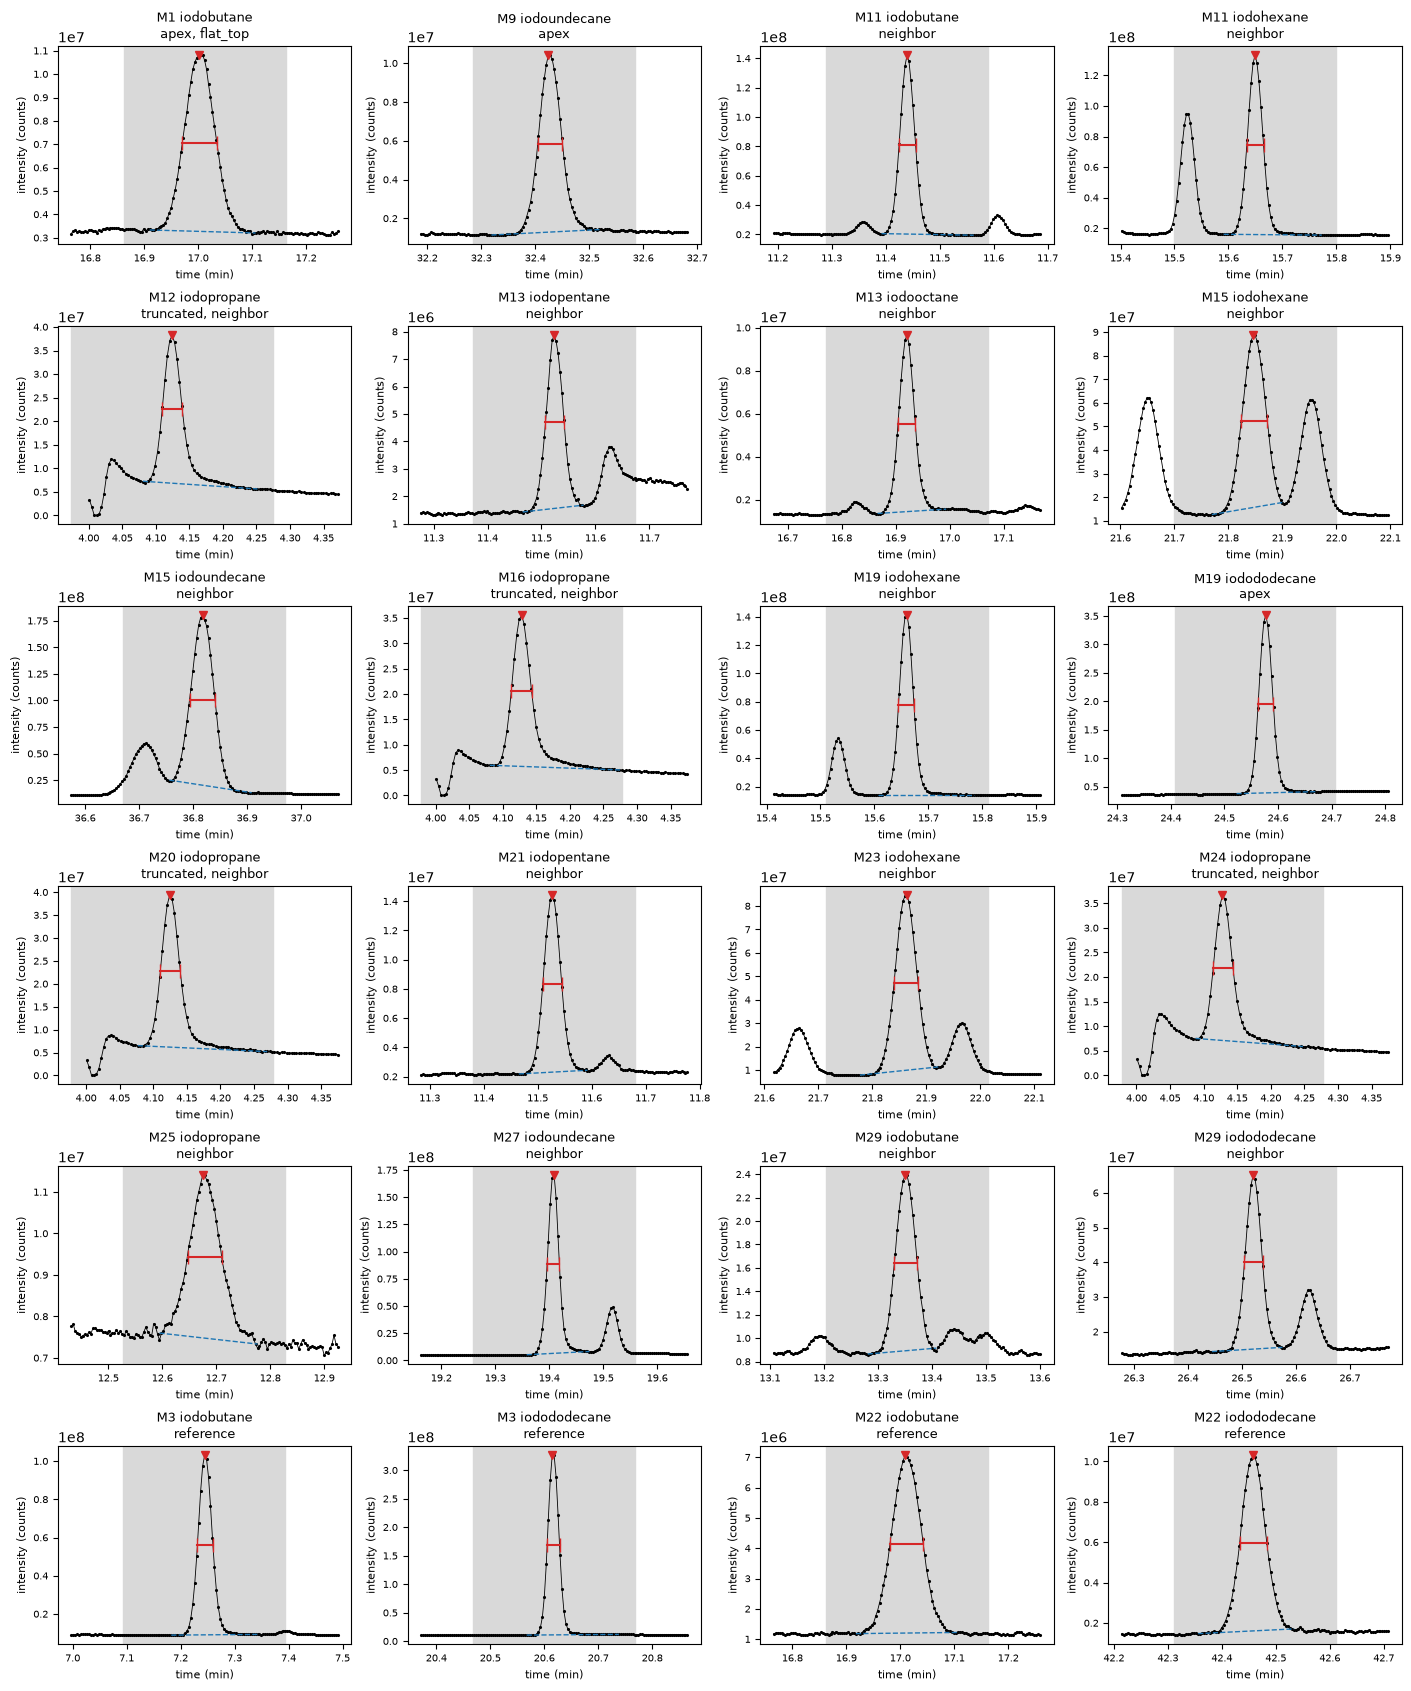

In [9]:
reference = peaks[
    peaks["method"].isin([int(label.split(" ")[1]) for label in example_labels])
    & peaks["elution_order"].isin([2, 11])
    & ~peaks["flagged"]
]
to_check = pd.concat([peaks[peaks["flagged"]], reference])

n_columns = 4
n_rows = -(-len(to_check) // n_columns)  # ceiling division
fig, axes = plt.subplots(n_rows, n_columns, figsize=(14, 2.8 * n_rows), layout="constrained")
for ax, row in zip(axes.flat, to_check.itertuples()):
    time, intensity = chromatograms[row.method]  # min, counts
    shown = np.abs(time - row.retention_time) <= CHECK_WINDOW_MIN
    ax.plot(time[shown], intensity[shown], color="black", linewidth=0.6, marker=".", markersize=2.5)
    ax.axvspan(row.retention_time - PEAK_WINDOW_MIN, row.retention_time + PEAK_WINDOW_MIN,
               color="0.85", zorder=0)

    def baseline_at(t):
        return np.interp(t, [row.baseline_t0, row.baseline_t1], [row.baseline_y0, row.baseline_y1])

    ax.plot([row.baseline_t0, row.baseline_t1], [row.baseline_y0, row.baseline_y1],
            color="tab:blue", linestyle="--", linewidth=1)
    half_level = baseline_at(row.apex_time) + row.height / 2  # counts
    ax.plot([row.left_time, row.right_time], [half_level, half_level],
            color="tab:red", linewidth=1.5, marker="|", markersize=10)
    ax.plot(row.apex_time, baseline_at(row.apex_time) + row.height,
            marker="v", color="tab:red", markersize=6, linestyle="none")

    flags = [name.removeprefix("flag_") for name in flag_columns if getattr(row, name)]
    ax.set_title(f"M{row.method} {row.standard}\n{', '.join(flags) if flags else 'reference'}", fontsize=9)
    ax.set_xlabel("time (min)", fontsize=8)
    ax.set_ylabel("intensity (counts)", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(to_check):]:
    ax.set_visible(False)
plt.show()

In all 20 flagged peaks and the 4 reference peaks the baseline runs along the signal at the valleys on both sides, the apex marker is on the top, and the half-height bar meets both flanks, including where an unlisted neighbor sits inside the window; the weakest case is iodoundecane in Method 15, whose partly merged neighbor leaves the left valley about 8 % of the peak height above the true baseline.

## Design structure and contrasts

Purpose: code the design as −1 (low) and +1 (high), find how it was built, and list the 31 contrasts that 32 runs can estimate, with what each one is aliased with.

Scientific choice: in a two-level fractional factorial, each contrast column measures a main effect or interaction together with its aliases, which the design cannot separate. The defining relation tells which effects share a column. The check below rebuilds it from the data instead of assuming it.

Expected output: F = ABC and G = ABDE, so I = ABCF = ABDEG = CDEFG, a resolution IV design: main effects are aliased only with three-factor or higher interactions. A table of 31 contrasts: 7 main effects, 18 two-factor-interaction columns (three of them holding two aliased pairs: AB = CF, AC = BF, AF = BC), and 6 higher-order columns.

In [10]:
FACTORS = list("ABCDEFG")
BASE_FACTORS = list("ABCDE")  # full 2^5 factorial; F and G are generated from these

coded = design.set_index("Method")[FACTORS].apply(lambda level: np.where(level == level.max(), 1, -1))
coded.index.name = "method"

f_generated = (coded["F"] == coded["A"] * coded["B"] * coded["C"]).all()
g_generated = (coded["G"] == coded["A"] * coded["B"] * coded["D"] * coded["E"]).all()
base_complete = len(coded[BASE_FACTORS].drop_duplicates()) == 2 ** len(BASE_FACTORS)
print(f"A-E form a full 2^5 factorial: {base_complete}; F = ABC: {f_generated}; G = ABDE: {g_generated}")

defining_words = [set("ABCF"), set("ABDEG")]
defining_words.append(defining_words[0] ^ defining_words[1])  # CDEFG
print("defining relation: I = " + " = ".join("".join(sorted(word)) for word in defining_words))


def aliases_of(letters):
    """All effects sharing a contrast column with `letters`, shortest first."""
    group = {frozenset(letters)} | {frozenset(set(letters) ^ word) for word in defining_words}
    return sorted(("".join(sorted(alias)) for alias in group), key=lambda name: (len(name), name))


contrast_columns = {}
contrast_info = []
for size in range(1, len(BASE_FACTORS) + 1):
    for letters in itertools.combinations(BASE_FACTORS, size):
        aliases = aliases_of(letters)
        shortest = len(aliases[0])
        label = " = ".join(name for name in aliases if len(name) == shortest)
        kind = {1: "main", 2: "2FI"}.get(shortest, "higher")
        contrast_columns[label] = coded[list(letters)].prod(axis=1)
        contrast_info.append({"contrast": label, "kind": kind, "aliases": ", ".join(aliases)})
contrasts = pd.DataFrame(contrast_columns)  # 32 methods x 31 contrasts, entries -1 or +1
contrast_info = pd.DataFrame(contrast_info).set_index("contrast")

orthogonal = (contrasts.T @ contrasts == np.eye(len(contrasts.columns)) * len(contrasts)).all().all()
print(f"{len(contrasts.columns)} contrasts, mutually orthogonal: {orthogonal}")
print(contrast_info["kind"].value_counts().to_dict())
print()
print(contrast_info.sort_values("kind", key=lambda k: k.map({"main": 0, "2FI": 1, "higher": 2})).to_string())

A-E form a full 2^5 factorial: True; F = ABC: True; G = ABDE: True
defining relation: I = ABCF = ABDEG = CDEFG
31 contrasts, mutually orthogonal: True
{'2FI': 18, 'main': 7, 'higher': 6}

             kind               aliases
contrast                               
A            main  A, BCF, BDEG, ACDEFG
B            main  B, ACF, ADEG, BCDEFG
C            main  C, ABF, DEFG, ABCDEG
D            main  D, ABEG, CEFG, ABCDF
E            main  E, ABDG, CDFG, ABCEF
F            main  F, ABC, CDEG, ABDEFG
G            main  G, ABDE, CDEF, ABCFG
AC = BF       2FI  AC, BF, ADEFG, BCDEG
AD            2FI  AD, BEG, BCDF, ACEFG
AE            2FI  AE, BDG, BCEF, ACDFG
BD            2FI  BD, AEG, ACDF, BCEFG
AF = BC       2FI  AF, BC, ACDEG, BDEFG
BE            2FI  BE, ADG, ACEF, BCDFG
CD            2FI  CD, EFG, ABDF, ABCEG
CE            2FI  CE, DFG, ABEF, ABCDG
AB = CF       2FI  AB, CF, DEG, ABCDEFG
DE            2FI  DE, ABG, CFG, ABCDEF
EG            2FI  EG, ABD, CDF, ABCEFG
AG          

## Effects of each factor on log height and log width

Purpose: estimate, for each standard separately, every contrast's effect on peak height and on FWHM.

Scientific choices:
- The responses are the natural logarithms of height and FWHM. Instrument settings act multiplicatively on peaks (a split ratio divides the amount reaching the column, a faster ramp shortens a peak by a factor), and heights span 150-fold across methods, so on a log scale an effect is the same size whether the peak is large or small, and `exp(effect)` reads as a ratio: the height or width at the high level divided by that at the low level.
- An effect is mean(response at +1) − mean(response at −1) = (contrast column · response) / 16.
- All 352 peaks are used, flagged ones included; Step 3 showed every flagged peak is measured correctly. Step 5 repeats the test without them.
- Because log(area) ≈ log(height) + log(FWHM) for a peak of fixed shape, the area ratio for each factor is the product of its height and width ratios. A setting that only changes the chromatography should trade height for width at nearly constant area; one that changes how much sample reaches the detector should change area.

Expected output: a table `effects` with one row per standard, response and contrast (11 × 2 × 31 = 682 rows); the main effects as ratios (rows: factors, columns: standards in elution order) for height and for FWHM; and the median ratios over standards for height, FWHM and area.

In [11]:
responses = {
    "height": np.log(peaks.pivot(index="method", columns="standard", values="height")),  # ln(counts)
    "fwhm": np.log(peaks.pivot(index="method", columns="standard", values="fwhm")),  # ln(min)
}
standards = list(retention_times.columns)  # in elution order

effect_tables = []
for response, values in responses.items():
    values = values.loc[contrasts.index, standards]
    table = contrasts.T @ values / (len(contrasts) / 2)  # contrasts x standards, change in ln(response)
    table = table.stack().rename("effect").reset_index().rename(columns={"level_0": "contrast"})
    table.insert(0, "response", response)
    effect_tables.append(table)
effects = pd.concat(effect_tables, ignore_index=True)
effects["kind"] = effects["contrast"].map(contrast_info["kind"])
effects["ratio"] = np.exp(effects["effect"])  # response at high level / response at low level
print(f"effects: {len(effects)} rows")

for response in responses:
    main_ratios = (effects[(effects["response"] == response) & (effects["kind"] == "main")]
                   .pivot(index="contrast", columns="standard", values="ratio")[standards])
    print()
    print(f"{response}: ratio high / low for each main effect")
    print(main_ratios.rename(columns=lambda name: name.removeprefix("iodo")).round(2).to_string())

median_ratio = (effects[effects["kind"] == "main"]
                .pivot_table(index="contrast", columns="response", values="effect", aggfunc="median"))
median_ratio["area"] = median_ratio["height"] + median_ratio["fwhm"]  # ln(area) = ln(height) + ln(fwhm) + const
print()
print("median ratio over the 11 standards (high / low)")
print(np.exp(median_ratio[["height", "fwhm", "area"]]).round(2).to_string())

effects: 682 rows

height: ratio high / low for each main effect
standard  propane  butane  pentane  hexane  benzene  heptane  octane  nonane  decane  undecane  dodecane
contrast                                                                                                
A            0.83    0.73     0.73    0.73     0.73     0.72    0.69    0.65    0.61      0.56      0.54
B            9.83    9.06     9.42    9.68    10.08     9.84    9.90   10.17   10.33     10.20     10.37
C            1.02    1.00     1.00    1.01     0.99     0.98    0.97    0.97    0.97      1.00      1.01
D            1.03    0.98     0.94    0.93     0.93     0.90    0.87    0.84    0.82      0.81      0.79
E            1.08    1.07     1.07    1.07     1.09     1.07    1.07    1.06    1.05      1.02      1.05
F            1.21    1.40     1.52    1.63     1.56     1.61    1.65    1.69    1.72      1.79      1.78
G            1.02    1.47     1.18    1.10     1.01     1.45    1.40    1.38    1.48      1.49 

## Main effects against elution order

Purpose: see, before any test, whether each factor's effect on height and on width is the same for early- and late-eluting standards.

Scientific choice: the effect is plotted as a ratio on a logarithmic axis, so that halving and doubling sit the same distance from 1 (no effect). Each factor has its own marker and line style, so the figure does not rely on color.

Expected output: two panels, height and FWHM, each with seven lines across the 11 standards in elution order. A flat line means the factor acts the same on early and late peaks; a sloped line means it does not.

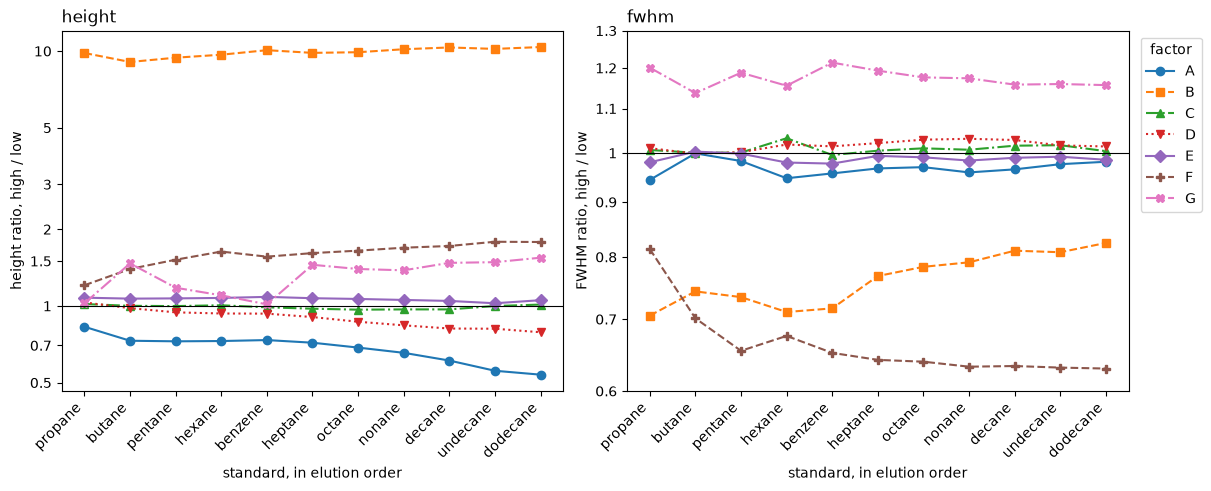

In [12]:
markers = ["o", "s", "^", "v", "D", "P", "X"]
line_styles = ["-", "--", "-.", ":", "-", "--", "-."]
order = np.arange(1, len(standards) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, (response, axis_label) in zip(axes, [("height", "height ratio, high / low"),
                                             ("fwhm", "FWHM ratio, high / low")]):
    for factor, marker, line_style in zip(FACTORS, markers, line_styles):
        ratios = (effects[(effects["response"] == response) & (effects["contrast"] == factor)]
                  .set_index("standard").loc[standards, "ratio"])
        ax.plot(order, ratios, marker=marker, linestyle=line_style, label=factor)
    ax.axhline(1, color="black", linewidth=0.8)
    ax.set_yscale("log")
    ax.set_xticks(order, [name.removeprefix("iodo") for name in standards], rotation=45, ha="right")
    ax.set_xlabel("standard, in elution order")
    ax.set_ylabel(axis_label)
    ax.set_title(response, loc="left")
axes[1].legend(title="factor", loc="upper left", bbox_to_anchor=(1.01, 1))
for ax, ticks in zip(axes, [[0.5, 0.7, 1, 1.5, 2, 3, 5, 10], [0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3]]):
    ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.set_yticks(ticks, [f"{tick:g}" for tick in ticks])
plt.show()

B raises height about tenfold for every standard and F and B narrow every peak, so they act on early and late standards alike in direction, but A, D and F change height more for late standards than for early ones (A from 0.83 for iodopropane to 0.54 for iodododecane), and G's effect on height jumps between neighboring standards instead of following elution order.

## Environment

Purpose: record the Python and package versions this notebook ran with. Expected output: Python 3.14 and the versions from `uv.lock`.

In [13]:
print(f"Python {sys.version.split()[0]}")
print(f"numpy {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"scipy {scipy.__version__}")
print(f"matplotlib {matplotlib.__version__}")

Python 3.14.7
numpy 2.5.3
pandas 3.0.6
scipy 1.18.1
matplotlib 3.11.2
